<a href="https://colab.research.google.com/github/Braden-Preston-dev/Machine-Learning-Practice/blob/main/HousingPricesPredictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model

In [7]:
df = pd.read_csv("Housing.csv")
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


Text(0, 0.5, 'Price($)')

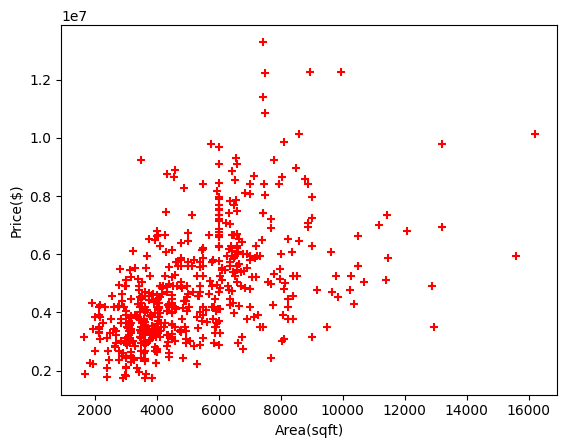

In [22]:
%matplotlib inline
plt.scatter(df.area, df.price, color='red', marker = '+')
plt.xlabel('Area(sqft)')
plt.ylabel('Price($)')

In [25]:
columns = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
df[columns] = df[columns].replace({"yes" : 1, "no" : 2})

/tmp/ipykernel_438/2556931130.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[columns] = df[columns].replace({"yes" : 1, "no" : 2})


In [31]:
reg = linear_model.LinearRegression()
X = df.drop(columns=['price', 'furnishingstatus'])
y = df.price
reg.fit(X, y)

LinearRegression()

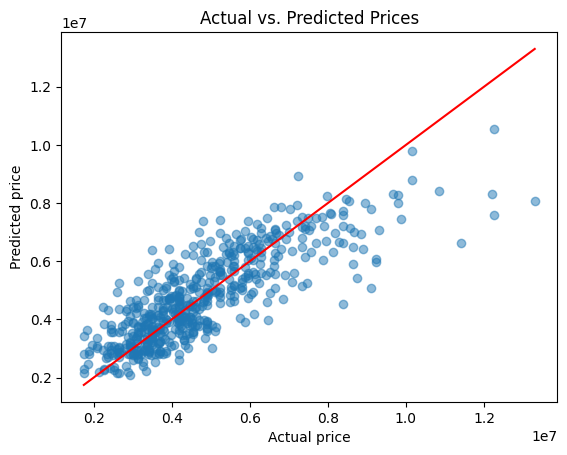

In [33]:
predictions = reg.predict(X)
plt.scatter(y, predictions, alpha=0.5)

# Reference line: perfect predictions
low = min(y.min(), predictions.min())
high = max(y.max(), predictions.max())
plt.plot([low, high], [low, high], color="red")

plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs. Predicted Prices")
plt.show()